In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

# Go one level up from the current working directory
ROOT_DIR = os.path.dirname(os.getcwd())

#Build Path
DATA_DIR = os.path.join(ROOT_DIR, "data", "raw")

# Load datasets
train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
#test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))

# EDA

## Introduction to the dataset 

In [47]:
train.sample(5)

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration,Churn
402116,307,M,Andrey,paid,Hill,1488695,1538470336000,Logged In,Logout,30448,"McAllen-Edinburg-Mission, TX",46,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,NaN,None,None,2018-10-02 08:52:16,2018-08-15 06:04:59,False
11230468,200,F,Claire,paid,Hernandez,1108863,1541226462000,Logged In,NextSong,151544,"Minneapolis-St. Paul-Bloomington, MN-WI",157,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,201.82159,Friends Don't Let Friends Dial Drunk,Plain White T's,2018-11-03 06:27:42,2018-08-27 09:39:25,False
22444299,200,F,Janell,free,Price,1771110,1542051770000,Logged In,NextSong,26022,"Washington-Arlington-Alexandria, DC-VA-MD-WV",28,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,259.23873,Rock Star,N.E.R.D.,2018-11-12 19:42:50,2018-05-24 08:28:55,False
25248884,307,F,Anna,paid,Price,1570565,1542044078000,Logged In,Thumbs Up,32727,"Salina, KS",73,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4...",PUT,NaN,None,None,2018-11-12 17:34:38,2018-09-13 06:10:23,False
23423816,200,F,Beverly,paid,Murphy,1554972,1539203716000,Logged In,NextSong,10708,"Burlington, IA-IL",22,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,257.12281,Eye-Land (Seasick rmx.),Moodorama,2018-10-10 20:35:16,2018-08-20 06:03:03,False


In [30]:
train.shape

# Dataset is composed of 17,499,636 observations of 19 features

(17499636, 19)

In [25]:
train.describe()

,status,ts,sessionId,itemInSession,length,time,registration,Churn
count,1.749964e+07,1.749964e+07,1.749964e+07,1.749964e+07,1.429143e+07,17499636,17499636,1.749964e+07
mean,2.091387e+02,1.540428e+12,8.480294e+04,1.055937e+02,2.487135e+02,2018-10-25 00:47:01.161927,2018-08-25 04:40:21.543066,2.440622e-04
min,2.000000e+02,1.538352e+12,1.000000e+00,0.000000e+00,5.220000e-01,2018-10-01 00:00:01,2017-10-14 22:05:25,0.000000e+00
25%,2.000000e+02,1.539340e+12,2.515900e+04,2.600000e+01,1.998885e+02,2018-10-12 10:33:57.750000,2018-08-10 21:14:59,0.000000e+00
50%,2.000000e+02,1.540397e+12,7.903800e+04,6.600000e+01,2.340828e+02,2018-10-24 15:58:54,2018-09-05 18:35:50,0.000000e+00
75%,2.000000e+02,1.541500e+12,1.383680e+05,1.440000e+02,2.768714e+02,2018-11-06 10:25:35,2018-09-20 17:24:57,0.000000e+00
max,4.040000e+02,1.542672e+12,2.070030e+05,1.426000e+03,3.024666e+03,2018-11-20 00:00:00,2018-11-19 23:34:34,1.000000e+00
std,3.023050e+01,1.233485e+09,6.141427e+04,1.168854e+02,9.722845e+01,NaN,NaN,1.562058e-02


In [ ]:
# Checking for missing values by columns
train.isna().sum()

# We observe that all missing values are located either length, song or artist with total 3,208,203 missing values


status                 0
gender                 0
firstName              0
level                  0
lastName               0
userId                 0
ts                     0
auth                   0
page                   0
sessionId              0
location               0
itemInSession          0
userAgent              0
method                 0
length           3208203
song             3208203
artist           3208203
time                   0
registration           0
Churn                  0
dtype: int64

In [84]:
train[train["song"].isna()].sample(3)
# These 3,208,203 missing values correspond to all the logs where page wasn't related to listening music
# No need to drop them !

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration,Churn
20382940,200,M,Luis,free,Thornton,1332666,1539616173000,Logged In,Roll Advert,8587,"New York-Newark-Jersey City, NY-NJ-PA",4,"""Mozilla/5.0 (Windows NT 6.3; WOW64) AppleWebK...",GET,NaN,None,None,2018-10-15 15:09:33,2018-09-15 04:36:46,False
12405208,307,F,Talia,paid,Ferguson,1077808,1541568690000,Logged In,Thumbs Down,163332,"Grand Junction, CO",36,"""Mozilla/5.0 (Windows NT 6.3; WOW64) AppleWebK...",PUT,NaN,None,None,2018-11-07 05:31:30,2018-07-07 22:45:08,False
6772326,200,M,Jeremiah,free,Hall,1966591,1540134101000,Logged In,Roll Advert,104211,"Lake Havasu City-Kingman, AZ",3,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",GET,NaN,None,None,2018-10-21 15:01:41,2018-08-30 17:47:21,False


In [ ]:
# Users are identified by their UserID, one UserID usually has multiple logs
print("Number of unique users:",train['userId'].nunique())

# Example : sample of the 10 first logs of user 1488695
train[train['userId']=='1488695'].sort_values(by='time').sample(10)

Number of unique users: 19140


,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration,Churn
14588067,307,M,Andrey,paid,Hill,1488695,1542150423000,Logged In,Thumbs Up,185037,"McAllen-Edinburg-Mission, TX",67,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,NaN,None,None,2018-11-13 23:07:03,2018-08-15 06:04:59,False
14838619,200,M,Andrey,paid,Hill,1488695,1542210798000,Logged In,NextSong,190642,"McAllen-Edinburg-Mission, TX",3,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,253.83138,Working Bees,The Pinker Tones,2018-11-14 15:53:18,2018-08-15 06:04:59,False
16112689,200,M,Andrey,paid,Hill,1488695,1542570585000,Logged In,NextSong,202296,"McAllen-Edinburg-Mission, TX",148,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,164.88444,Halo,Deep Blue Something,2018-11-18 19:49:45,2018-08-15 06:04:59,False
508323,200,M,Andrey,paid,Hill,1488695,1538496868000,Logged In,Home,30448,"McAllen-Edinburg-Mission, TX",187,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",GET,NaN,None,None,2018-10-02 16:14:28,2018-08-15 06:04:59,False
5436048,200,M,Andrey,free,Hill,1488695,1539788830000,Logged In,NextSong,90546,"McAllen-Edinburg-Mission, TX",38,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,89.36444,Build High,Pixies,2018-10-17 15:07:10,2018-08-15 06:04:59,False
255945,200,M,Andrey,paid,Hill,1488695,1538428620000,Logged In,NextSong,5221,"McAllen-Edinburg-Mission, TX",224,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,181.62893,El Elefante,Caifanes,2018-10-01 21:17:00,2018-08-15 06:04:59,False
13841770,307,M,Andrey,paid,Hill,1488695,1541963567000,Logged In,Add Friend,179234,"McAllen-Edinburg-Mission, TX",369,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,NaN,None,None,2018-11-11 19:12:47,2018-08-15 06:04:59,False
13021675,307,M,Andrey,free,Hill,1488695,1541713021000,Logged In,Logout,170732,"McAllen-Edinburg-Mission, TX",12,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,NaN,None,None,2018-11-08 21:37:01,2018-08-15 06:04:59,False
6416863,200,M,Andrey,free,Hill,1488695,1539999642000,Logged In,Roll Advert,97966,"McAllen-Edinburg-Mission, TX",10,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",GET,NaN,None,None,2018-10-20 01:40:42,2018-08-15 06:04:59,False
10557131,200,M,Andrey,free,Hill,1488695,1541070952000,Logged In,NextSong,146526,"McAllen-Edinburg-Mission, TX",26,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,149.75955,Dumb,Nirvana,2018-11-01 11:15:52,2018-08-15 06:04:59,False


In [3]:
# We identify the target variable "Cancellation Confirmation" & "Cancel"

train["page"].value_counts()

page
NextSong                     14291433
Thumbs Up                      789391
Home                           645259
Add to Playlist                409606
Roll Advert                    284837
Add Friend                     262147
Logout                         204700
Thumbs Down                    164964
Downgrade                      124248
Settings                       101191
Help                            89035
Upgrade                         37696
About                           33117
Save Settings                   20370
Error                           17294
Submit Upgrade                  11381
Submit Downgrade                 4425
Cancellation Confirmation        4271
Cancel                           4271
Name: count, dtype: int64

In [ ]:
# Computing the number of users having only used the free version, only the paid version, and the free + paid version

user_types = train.groupby('userId')['level'].agg(
    lambda x: set(x.dropna())
)

# User classification
print("Free subscription only :", user_types.apply(lambda x: x == {'free'}).sum())
print("Paid subscription only :", user_types.apply(lambda x: x == {'paid'}).sum())
print("Both:", user_types.apply(lambda x: x == {'free', 'paid'}).sum())

# the numbers below correctly add up to retrieve the number of unique users : 19,140

Free subscription only : 5963
Paid subscription only : 3158
Both: 10019


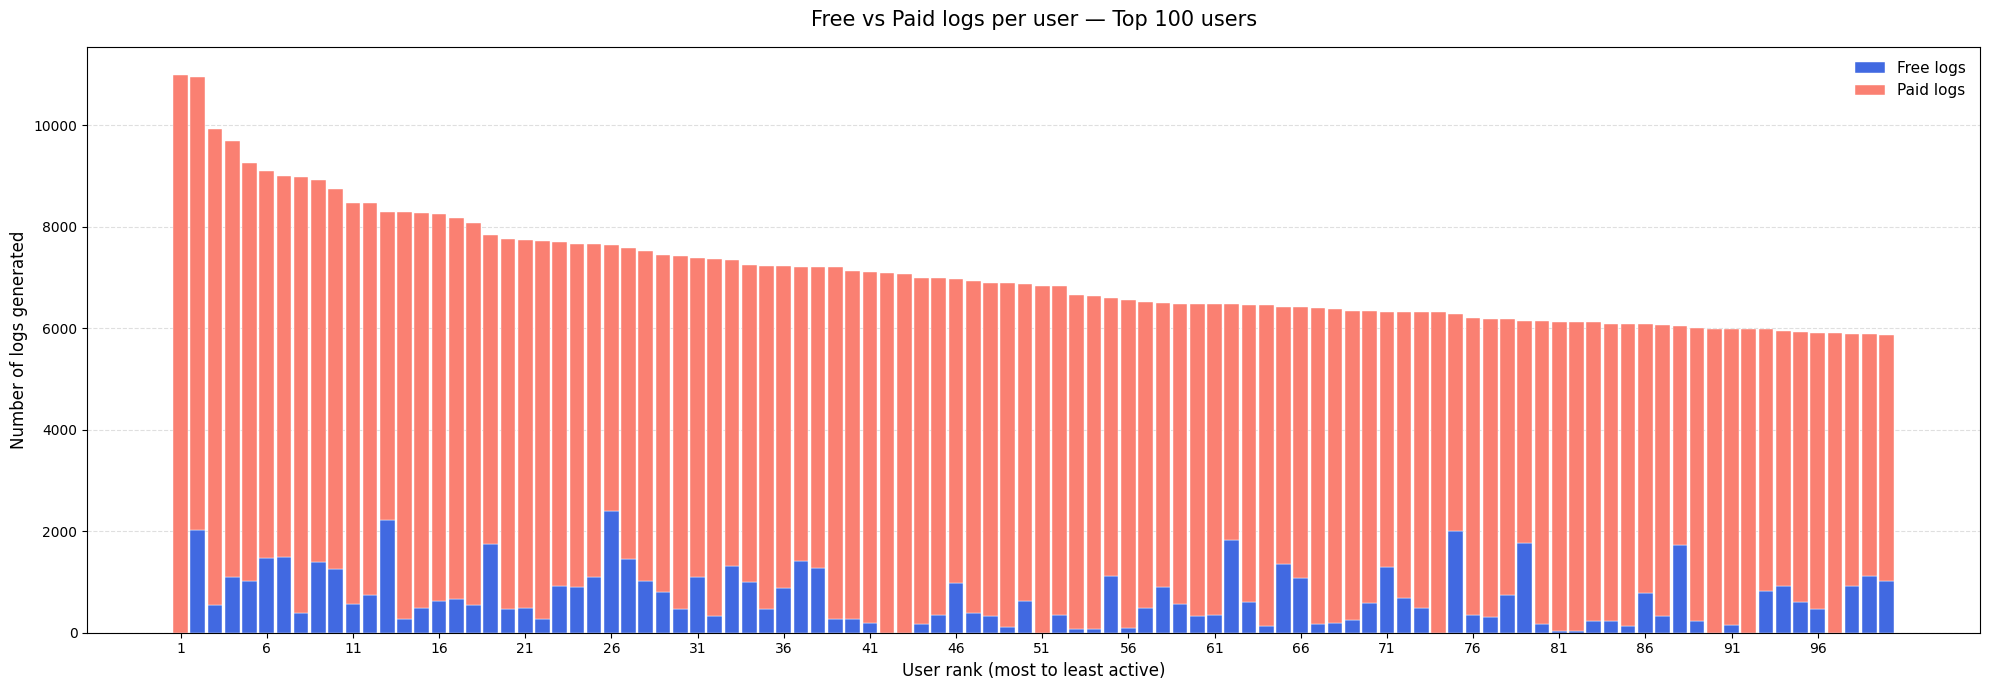

In [82]:
import matplotlib.pyplot as plt
import numpy as np

# Count logs per user and subscription type
df_users = (
    train.groupby(['userId', 'level'])
    .size()
    .unstack(fill_value=0)
)

# Rank users by total logs
df_users['totalLogs'] = df_users['free'] + df_users['paid']
df_users = df_users.sort_values('totalLogs', ascending=False)

# Keep top 100 users
df_plot = df_users.head(100)

# Plot
fig, ax = plt.subplots(figsize=(20, 7))

x = np.arange(1, len(df_plot) + 1)

ax.bar(x, df_plot['free'], width=0.85, color='royalblue',
       label='Free logs', edgecolor='white', linewidth=0.3)

ax.bar(x, df_plot['paid'], width=0.85, bottom=df_plot['free'],
       color='salmon', label='Paid logs',
       edgecolor='white', linewidth=0.3)

ax.set_xlabel('User rank (most to least active)', fontsize=12)
ax.set_ylabel('Number of logs generated', fontsize=12)
ax.set_title('Free vs Paid logs per user — Top 100 users',
             fontsize=15, pad=15)

ax.set_xticks(np.arange(1, 101, 5))
ax.tick_params(axis='both', labelsize=10)

ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

ax.legend(fontsize=11, frameon=False)

plt.tight_layout()
plt.show()

In [ ]:
# We see that users switching from free to paid subscription substantially increase the use of the streaming service
# Churners could surepresented be among the users that did not decide to switch to paid subscription

## Defining Churn target 

In [ ]:
# Isolating the target variable in Churn (boolean True or False)

train["Churn"] = (train["page"]=="Cancellation Confirmation")

In [ ]:
print("Number of Churners:",f"{train['Churn'].sum():,}")
print("Number of Non-Churners",f"{(train['userId'].nunique()) - (train['Churn'].sum()):,}")
print("Number of logs not related to Churning", f"{train.shape[0]-(train['Churn'].sum()):,}")

# The number of users churning is low compared to the number of users who do not (1:3) and
# even lower when considering the number of logs concerning the cancellation (4k vs 17,5 M).
# This hints a possible class imbalance when it will come to predictions (more likely to predict non churners (0))

# Hence the need to use the balanced accuracy, as demanded by the subject : the balanced accuracy gives equal importance to
# the number of correct predictions of 0 and 1. This is relevant as in this case, predicting mostly 0 could yield a very high
# accuracy as most client do not resign their subscription but it is clear that the company is economically much more interested
# to accurately predict the potential churners to try to keep them in !

Number of Churners: 4,271
Number of Non-Churners 14,869
Number of logs not related to Churning 17,495,365
